## Imports

In [1]:
import os

from alphagenome.data import genome
from alphagenome.visualization import plot_components
from alphagenome_research.model import dna_model
from alphagenome.models import dna_client
import matplotlib.pyplot as plt
import pandas as pd

/data/Dcode/gaetano/conda/envs/alphagenome_clean/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Local Model Alpha Genome

In [2]:
# Load model using persistent HF auth and local FASTA override
import os
from pathlib import Path
from getpass import getpass
from huggingface_hub import whoami, login
from alphagenome_research.model import dna_model
from alphagenome.models import dna_model as public_dna_model


def ensure_hf_auth(allow_prompt=True):
    try:
        info = whoami()
        print(f"HF already authenticated as: {info.get('name', 'unknown')}")
        return
    except Exception:
        pass

    token = os.getenv("HF_TOKEN") or os.getenv("HUGGINGFACEHUB_API_TOKEN")
    if token:
        login(token=token, add_to_git_credential=False, skip_if_logged_in=True)
        info = whoami()
        print(f"HF authenticated via environment token as: {info.get('name', 'unknown')}")
        return

    if allow_prompt:
        try:
            token = getpass("Enter Hugging Face token (input hidden): ").strip()
        except Exception:
            token = ""

        if token:
            login(token=token, add_to_git_credential=False, skip_if_logged_in=True)
            info = whoami()
            print(f"HF authenticated via interactive prompt as: {info.get('name', 'unknown')}")
            return

    raise RuntimeError(
        "No Hugging Face credentials found. Use one of:\n"
        "1) Run `hf auth login` in a terminal\n"
        "2) Set HF_TOKEN (or HUGGINGFACEHUB_API_TOKEN)\n"
        "3) Re-run this cell and paste a token when prompted"
    )


def resolve_local_human_fasta_path():
    candidates = [
        os.getenv("ALPHAGENOME_FASTA"),
        "/data/Dcode/gaetano/repos/fasta_files/hg38.fa",
    ]
    for candidate in candidates:
        if candidate and Path(candidate).exists():
            return candidate
    return None


def resolve_local_mouse_fasta_path():
    candidates = [
        os.getenv("ALPHAGENOME_MOUSE_FASTA"),
        "/data/Dcode/gaetano/repos/fasta_files/mm10.fa",
        "/data/Dcode/gaetano/repos/fasta_files/mm39.fa",
    ]
    for candidate in candidates:
        if candidate and Path(candidate).exists():
            return candidate
    return None


ensure_hf_auth(allow_prompt=True)

human_fasta = resolve_local_human_fasta_path()
if not human_fasta:
    raise FileNotFoundError(
        "No local human FASTA found. Set ALPHAGENOME_FASTA to a local GRCh38 FASTA path, e.g.\n"
        "export ALPHAGENOME_FASTA=/path/to/GRCh38.p13.genome.fa"
    )

mouse_fasta = resolve_local_mouse_fasta_path()
if mouse_fasta:
    print(f"Using local mouse FASTA: {mouse_fasta}")
else:
    print(
        "No local mouse FASTA found; configuring mouse organism without local FASTA. "
        "Predictions on human intervals still work."
    )

print(f"Using local human FASTA: {human_fasta}")
organism_settings = {
    public_dna_model.Organism.HOMO_SAPIENS: dna_model.OrganismSettings(
        fasta_path=human_fasta,
    ),
    public_dna_model.Organism.MUS_MUSCULUS: dna_model.OrganismSettings(
        fasta_path=mouse_fasta,
    ) if mouse_fasta else dna_model.OrganismSettings(),
}

model = dna_model.create_from_huggingface("fold-1", organism_settings=organism_settings)
print("Model loaded successfully.")

HF already authenticated as: tanoManzo
No local mouse FASTA found; configuring mouse organism without local FASTA. Predictions on human intervals still work.
Using local human FASTA: /data/Dcode/gaetano/repos/fasta_files/hg38.fa


Fetching 12 files: 100%|██████████| 12/12 [00:00<00:00, 46863.73it/s]


Model loaded successfully.


In [3]:
output_metadata = model.output_metadata(dna_client.Organism.HOMO_SAPIENS).concatenate()
output_metadata

,name,strand,Assay title,ontology_curie,biosample_name,biosample_type,biosample_life_stage,data_source,endedness,genetically_modified,nonzero_mean,output_type,gtex_tissue,histone_mark,transcription_factor
0,CL:0000084 ATAC-seq,.,ATAC-seq,CL:0000084,T-cell,primary_cell,adult,encode,paired,False,0.739741,OutputType.ATAC,NaN,NaN,NaN
1,CL:0000100 ATAC-seq,.,ATAC-seq,CL:0000100,motor neuron,in_vitro_differentiated_cells,adult,encode,paired,False,0.273136,OutputType.ATAC,NaN,NaN,NaN
2,CL:0000236 ATAC-seq,.,ATAC-seq,CL:0000236,B cell,primary_cell,adult,encode,paired,False,4.700081,OutputType.ATAC,NaN,NaN,NaN
3,CL:0000623 ATAC-seq,.,ATAC-seq,CL:0000623,natural killer cell,primary_cell,adult,encode,paired,False,0.938715,OutputType.ATAC,NaN,NaN,NaN
4,CL:0000624 ATAC-seq,.,ATAC-seq,CL:0000624,"CD4-positive, alpha-beta T cell",primary_cell,adult,encode,paired,False,4.365206,OutputType.ATAC,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7,ENCSR182QNJ,-,PRO-cap,EFO:0001099,Caco-2,cell_line,NaN,encode,NaN,False,14.002803,OutputType.PROCAP,NaN,NaN,NaN
8,ENCSR740IPL,-,PRO-cap,EFO:0002067,K562,cell_line,NaN,encode,NaN,False,15.765458,OutputType.PROCAP,NaN,NaN,NaN
9,ENCSR797DEF,-,PRO-cap,EFO:0002819,Calu3,cell_line,NaN,encode,NaN,False,12.281321,OutputType.PROCAP,NaN,NaN,NaN
10,ENCSR801ECP,-,PRO-cap,CL:0002618,endothelial cell of umbilical vein,primary_cell,NaN,encode,NaN,False,13.973692,OutputType.PROCAP,NaN,NaN,NaN


## Predictions 

In [10]:
silencer =        "chr12:111,598,679-111,598,729"
open_chrom_peak = "chr12:111,597,329-111,600,184"

variant = genome.Variant(
    chromosome='chr12', 
    position=(111598729 + 111598679) // 2,
    reference_bases='C', #it does not matter for this synthetic variant
    alternate_bases= 'N'*400
)

print(f"Variant created: {variant.chromosome}:{variant.position}")
print(f"  REF: {variant.reference_bases}")
print(f"  ALT: {variant.alternate_bases[:50]}... ({len(variant.alternate_bases)} bp)")

Variant created: chr12:111598704
  REF: C
  ALT: NNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNN... (400 bp)


In [11]:
# Hansen & Hodges 2022 (Genome Res, ATAC-STARR-seq) profiled GM12878 lymphoblastoid cells.
biosample_of_interest = ["GM12878"]

# Find matching ontology terms for each biosample
matching_terms = {}
for term in biosample_of_interest:
    matches = output_metadata[output_metadata['biosample_name'] == term]['ontology_curie'].unique()
    if len(matches) > 0:
        matching_terms[term] = matches[0]  # Take first match
        print(f"✓ {term:45} → {matches[0]}")
    else:
        print(f"✗ {term:45} → NOT FOUND")


print(f"\nFound {len(matching_terms)} / {len(biosample_of_interest)} biosamples")
print(f"\nOntology terms for prediction: {list(matching_terms.values())}")

gm_tracks = output_metadata[output_metadata['ontology_curie'].isin(matching_terms.values())]
print(gm_tracks.groupby('output_type').size())

✓ GM12878                                       → EFO:0002784

Found 1 / 1 biosamples

Ontology terms for prediction: ['EFO:0002784']
output_type
OutputType.ATAC                   1
OutputType.CAGE                   2
OutputType.DNASE                  1
OutputType.RNA_SEQ                5
OutputType.CHIP_HISTONE           8
OutputType.CHIP_TF              101
OutputType.SPLICE_SITE_USAGE      4
OutputType.SPLICE_JUNCTIONS       2
OutputType.CONTACT_MAPS           1
dtype: int64


In [12]:
interval = variant.reference_interval.resize(dna_client.SEQUENCE_LENGTH_100KB)
variant_output = model.predict_variant(
    interval=interval,
    variant=variant,
    requested_outputs=[
        dna_client.OutputType.RNA_SEQ,
        dna_client.OutputType.CONTACT_MAPS,
        dna_client.OutputType.CHIP_HISTONE,
        dna_client.OutputType.DNASE,
        dna_client.OutputType.ATAC,
        dna_client.OutputType.CAGE
    ],
    ontology_terms=list(matching_terms.values()),
) 

print("Prediction complete!")

Prediction complete!


In [13]:
import pyranges
from alphagenome.data import gene_annotation
from alphagenome.data import transcript as transcript_utils

GTF_PATH = '/data/Dcode/gaetano/projects/Writing_Scientific_Manuscript_Codex/data/gencode/gencode.v50.basic.annotation.gtf.gz'

# Parsing the full GENCODE GTF takes ~2 min.
gtf = pyranges.read_gtf(GTF_PATH).df
gtf = gtf[gtf.Chromosome == variant.chromosome]
gtf = gene_annotation.filter_protein_coding(gtf)
gtf = gene_annotation.filter_to_longest_transcript(gtf)

transcripts = transcript_utils.TranscriptExtractor(gtf).extract(interval)
print(f"Transcripts in interval: {[t.info.get('gene_name') for t in transcripts]}")

Transcripts in interval: ['ATXN2', 'BRAP']


/data/Dcode/gaetano/conda/envs/alphagenome_clean/lib/python3.11/site-packages/alphagenome/data/transcript.py:662: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for chromosome, dfc in df.groupby('Chromosome')


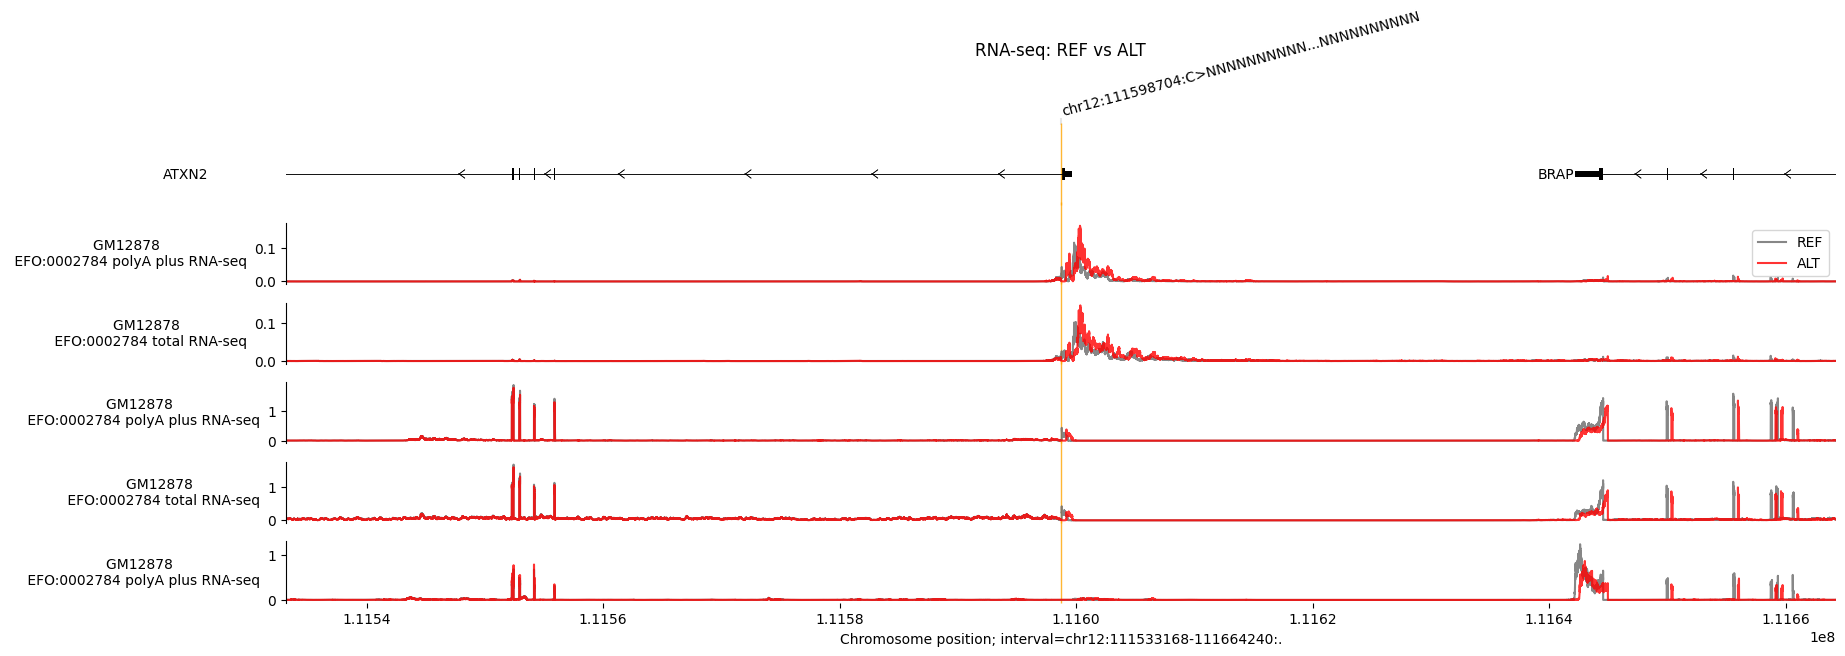

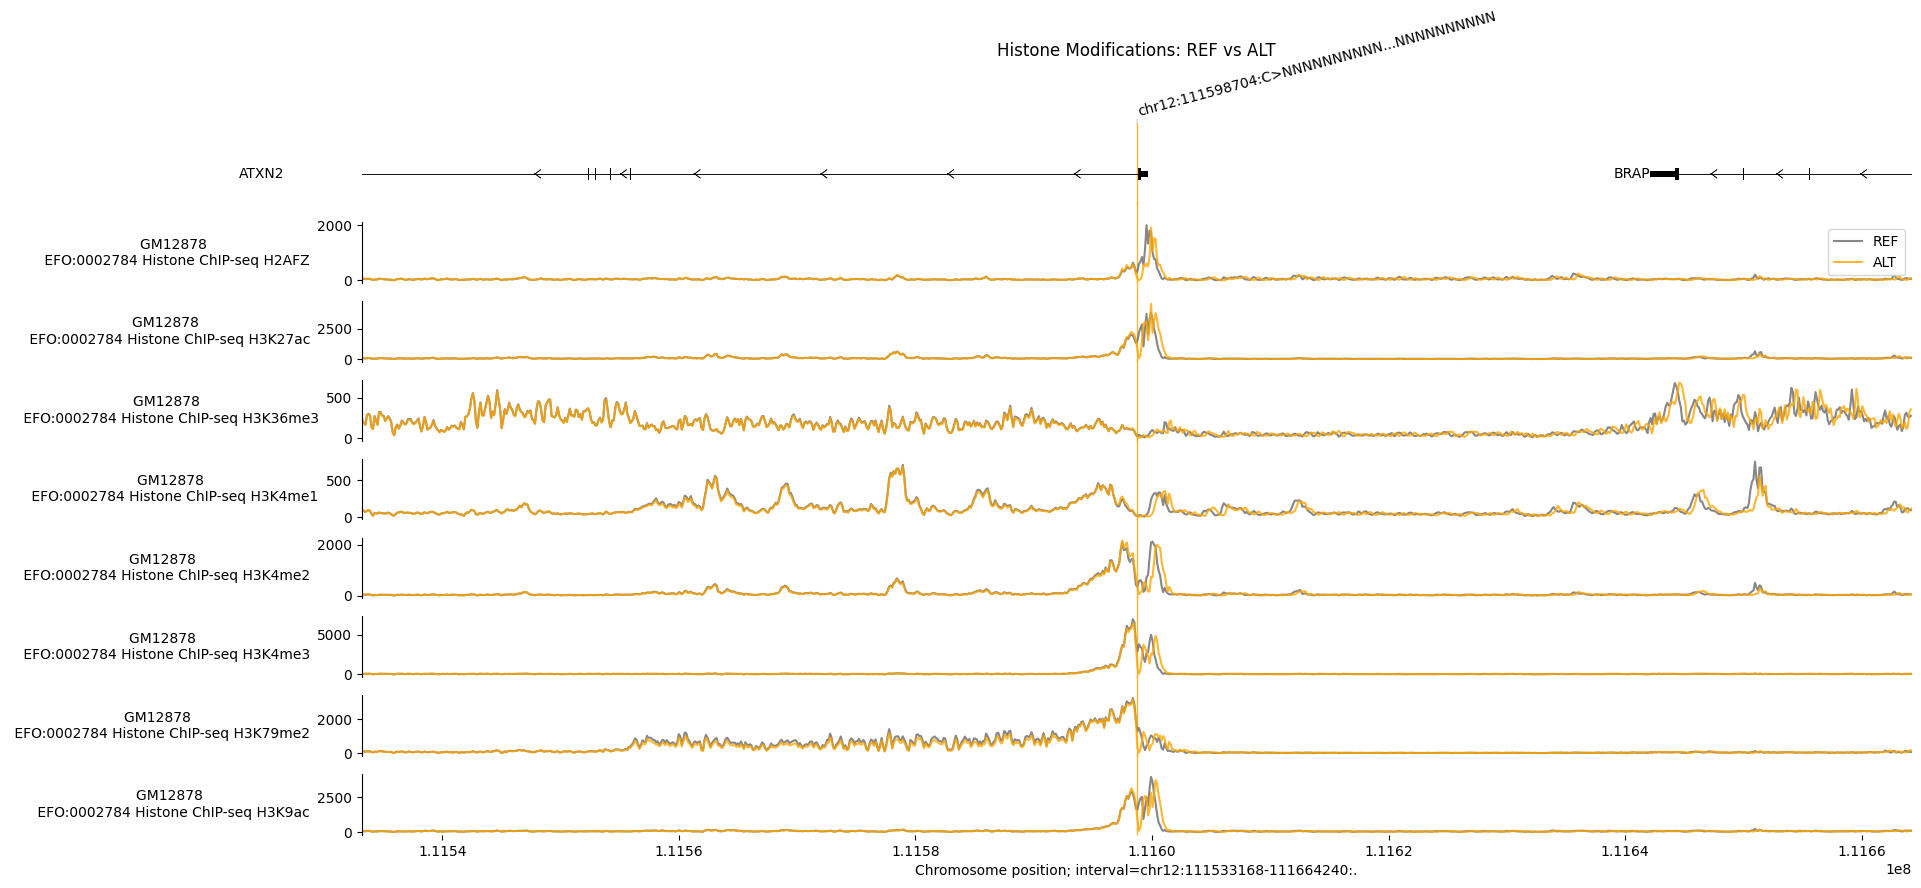

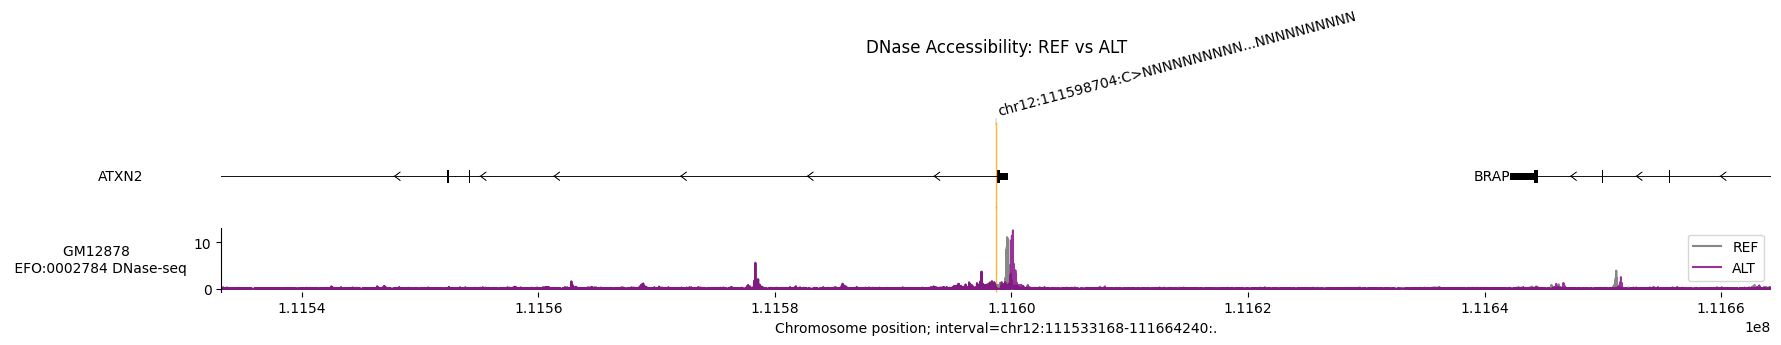

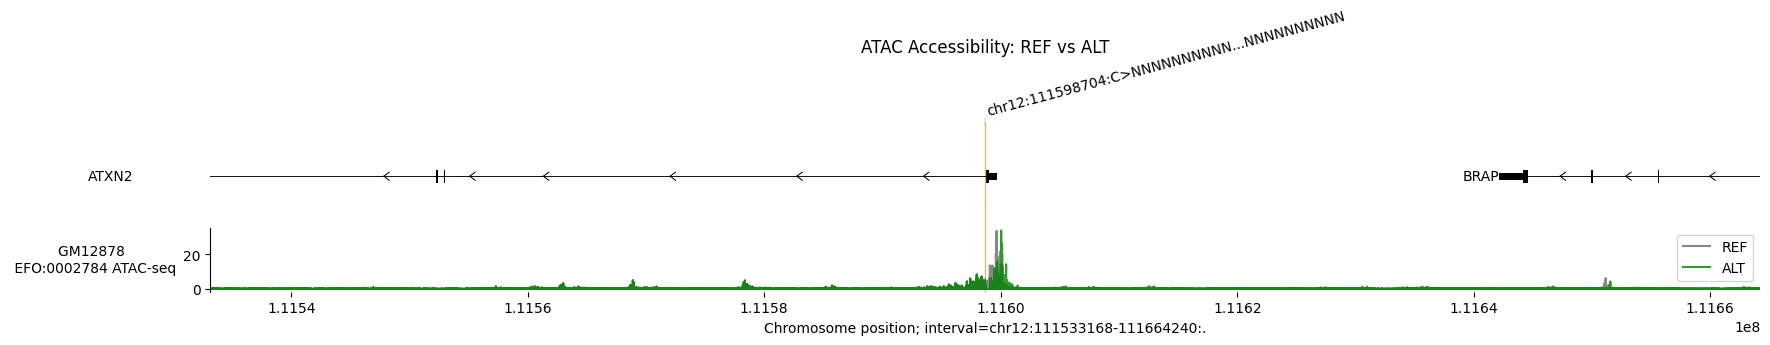

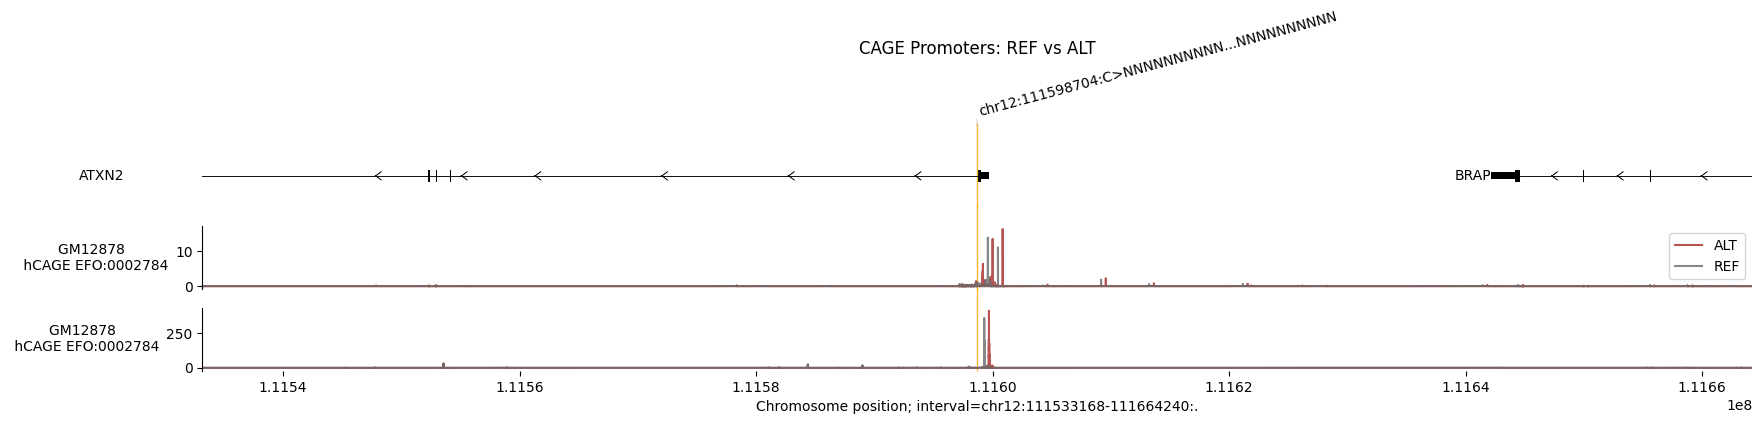

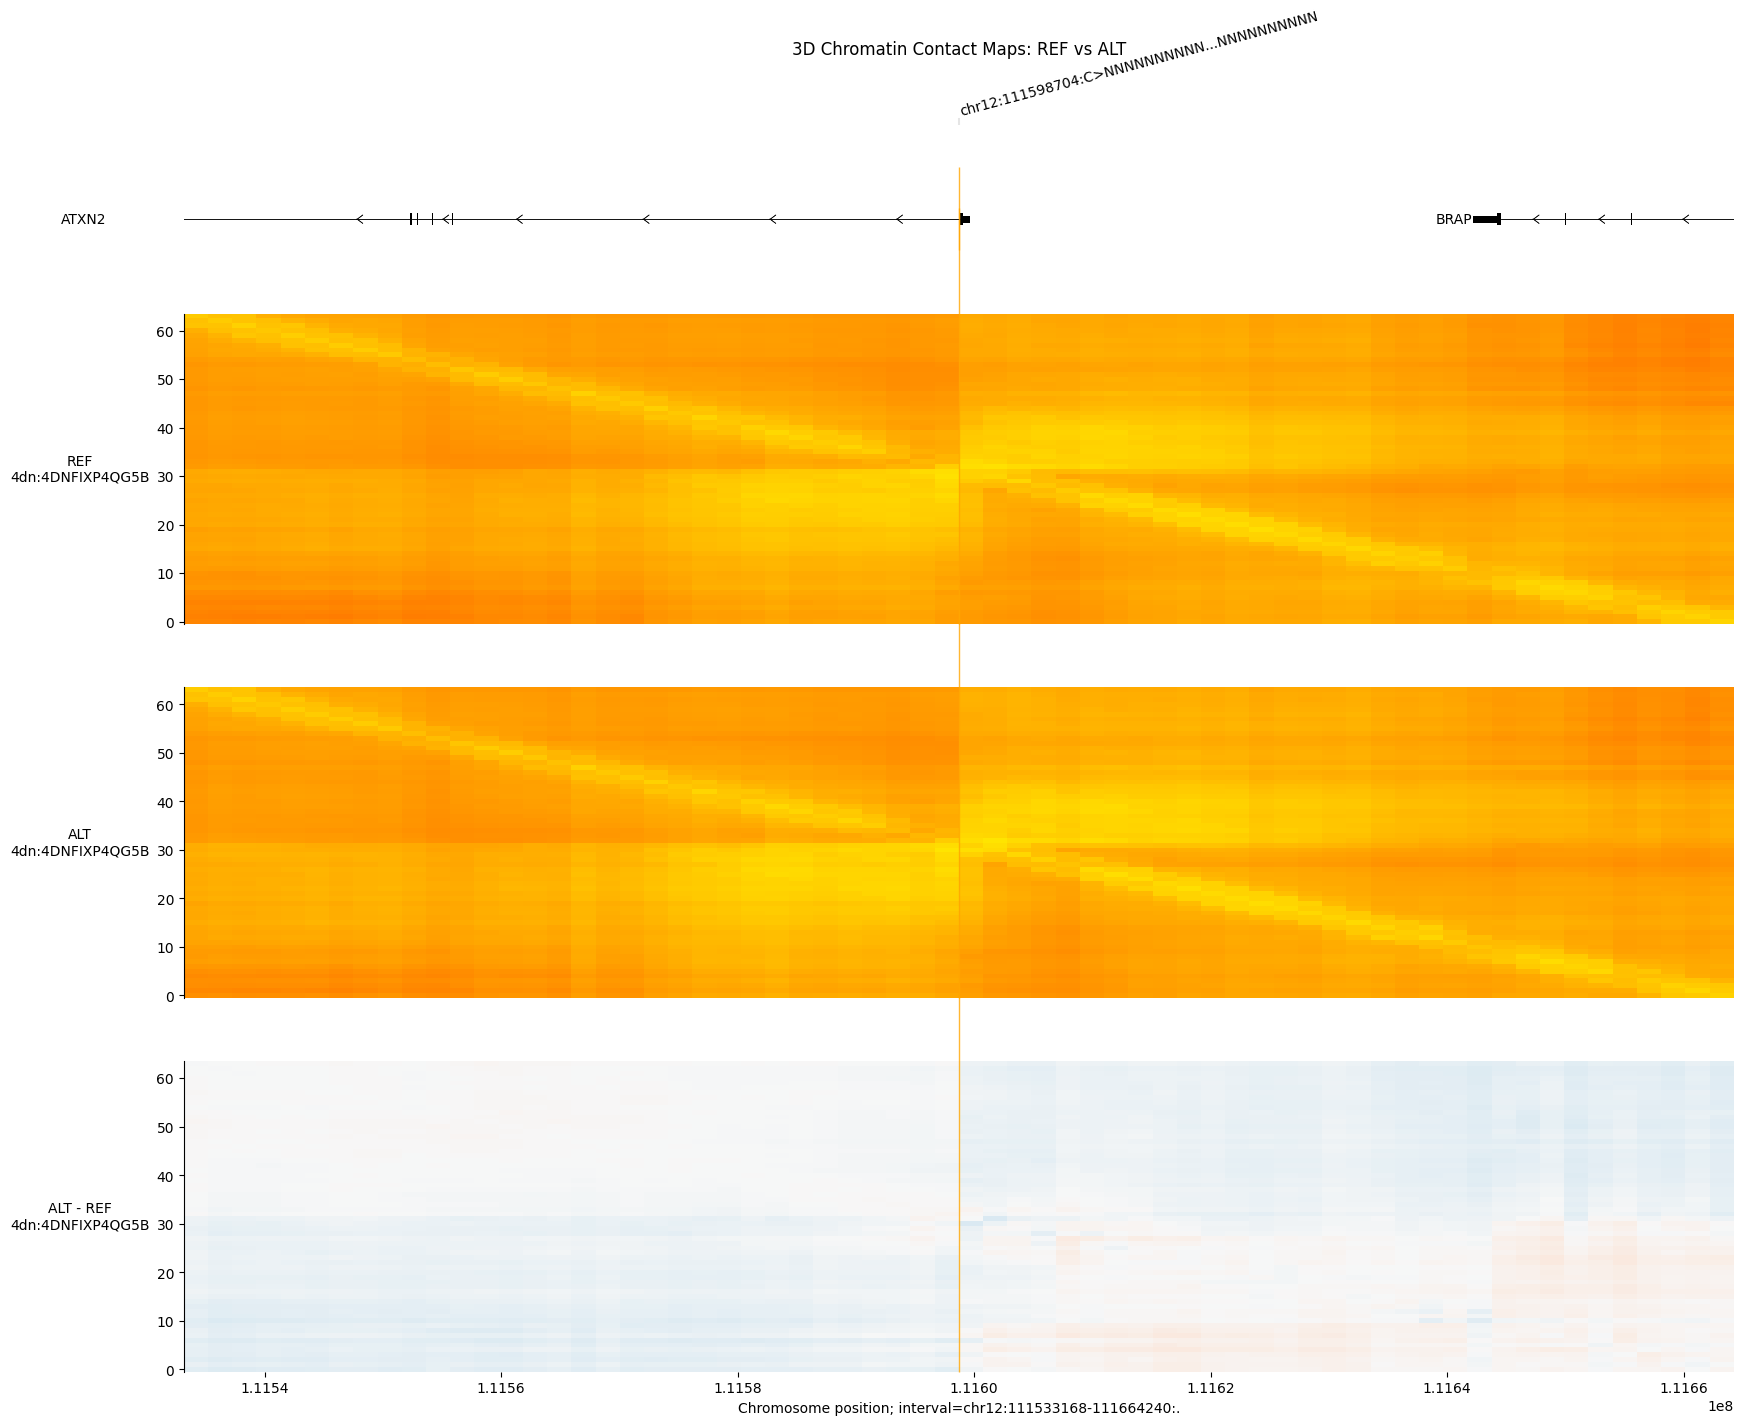

In [14]:
track_plots = [
    ('rna_seq', 'RNA-seq', 'red'),
    ('chip_histone', 'Histone Modifications', 'orange'),
    ('dnase', 'DNase Accessibility', 'purple'),
    ('atac', 'ATAC Accessibility', 'green'),
    ('cage', 'CAGE Promoters', 'brown'),
]

for attr, title, color in track_plots:
    ref = getattr(variant_output.reference, attr)
    alt = getattr(variant_output.alternate, attr)
    if ref is None or ref.num_tracks == 0:
        print(f"No {title} tracks for the selected biosamples")
        continue
    plot_components.plot(
        [
            plot_components.TranscriptAnnotation(transcripts),
            plot_components.OverlaidTracks(
                tdata={'REF': ref, 'ALT': alt},
                colors={'REF': 'dimgrey', 'ALT': color},
                ylabel_template='{biosample_name} \n {name}',
            ),
        ],
        interval=ref.interval,
        annotations=[plot_components.VariantAnnotation([variant], alpha=0.8)],
        title=f'{title}: REF vs ALT',
    )
    plt.show()

# Contact maps: REF, ALT and ALT - REF for each track
ref_cm = variant_output.reference.contact_maps
alt_cm = variant_output.alternate.contact_maps
if ref_cm is None or ref_cm.num_tracks == 0:
    print("No contact map tracks for the selected biosamples")
else:
    for i in range(ref_cm.num_tracks):
        ref_i = ref_cm.select_tracks_by_index([i])
        alt_i = alt_cm.select_tracks_by_index([i])
        plot_components.plot(
            [
                plot_components.TranscriptAnnotation(transcripts),
                plot_components.ContactMaps(ref_i, ylabel_template='REF\n{name}', track_height=5),
                plot_components.ContactMaps(alt_i, ylabel_template='ALT\n{name}', track_height=5),
                plot_components.ContactMapsDiff(alt_i - ref_i, ylabel_template='ALT - REF\n{name}', track_height=5),
            ],
            interval=ref_cm.interval,
            annotations=[plot_components.VariantAnnotation([variant], alpha=0.8)],
            title='3D Chromatin Contact Maps: REF vs ALT',
        )
        plt.show()